\Delta: 5, n: 50, Lmin: 3, Lmax: 3


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/528 [00:00<?, ?it/s]

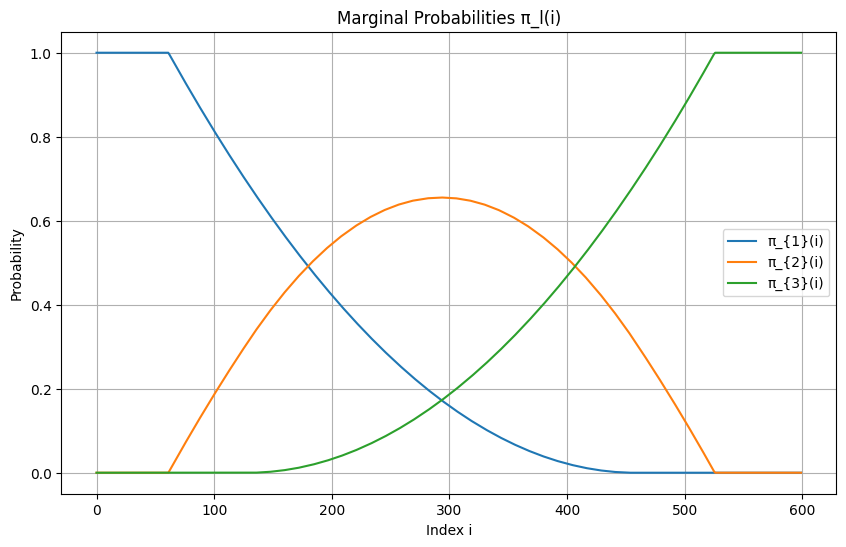

In [15]:
import numpy as np
import WERM.config
import matplotlib.pyplot as plt

L_is_upper_bound = False
n = 600
p = 400
delta_fraction = 1/10
Delta_n = int(delta_fraction * n)
L = 3
if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
    if L_is_upper_bound:
        pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
    else: 
        pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # Populate the pi L times n matrix
    pi = np.zeros((L, n))
    for l in range(L):
        for i in range(n):
            pi[l, i] = pi_i_l(L, l + 1, i + 1)
else:
    n_small = 50
    Delta_n_small = int(Delta_n * n_small/n)
    if L_is_upper_bound: 
        p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
        Lmin = 1
        Lmax = L
    else:
        p_l = None
        Lmin = L
        Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)

# Plot each row of pi
plt.figure(figsize=(10, 6))
for l in range(L):
    plt.plot(pi[l, :], label=f'π_{{{l+1}}}(i)')
plt.title('Marginal Probabilities π_l(i)')
plt.xlabel('Index i')
plt.ylabel('Probability')
plt.legend()
plt.grid()
plt.show()

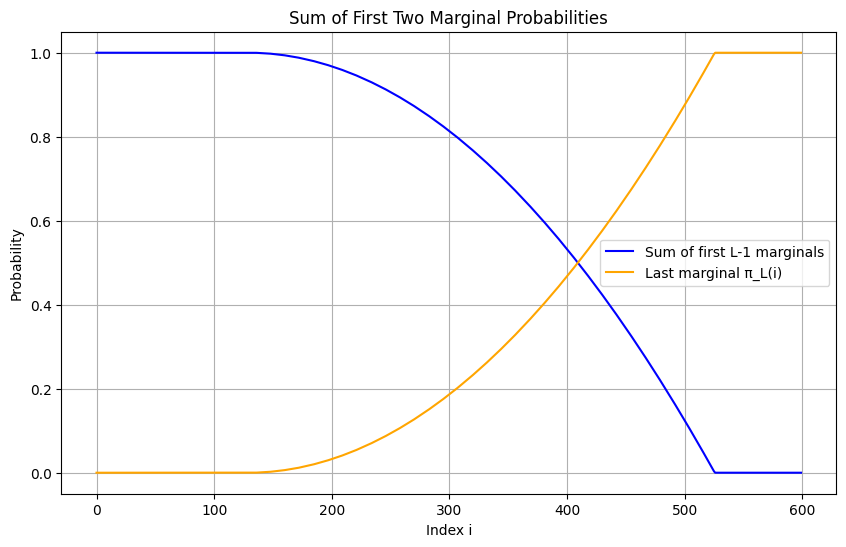

In [12]:
# Add the first L-1 rows and plot against the last row
plt.figure(figsize=(10, 6))
plt.plot(np.sum(pi[:-1, :], axis=0), label='Sum of first L-1 marginals', color='blue')
plt.plot(pi[-1, :], label='Last marginal π_L(i)', color='orange')
plt.title('Sum of First Two Marginal Probabilities')
plt.xlabel('Index i')
plt.ylabel('Probability')
plt.legend()
plt.grid()
plt.show()

In [17]:
# Compute the integral of the orange line (the last row) from index 410 onwards, and compare it with the integral of the orange line from index 0 to 410
integral_last_row = np.trapz(pi[-1, 410:], dx=1)
integral_first_part = np.trapz(pi[-1, :410], dx=1)
print(f'Integral of last row from index 410 onwards: {integral_last_row}')
print(f'Integral of last row from index 0 to 410: {integral_first_part}')
print(f'Ratio (last part / first part): {integral_last_row / integral_first_part}')

Integral of last row from index 410 onwards: 158.61010716470253
Integral of last row from index 0 to 410: 46.668052043843694
Ratio (last part / first part): 3.398687115024461
